### Task 1

In [1]:
import json, os, platform

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision

from models import Teacher, load_student
from utils import kd_loss, evaluate, train
from efficientp import profile
import data

SEED = 0
EPOCHS = 5
LR = 1e-3
BATCH_SIZE = 32
device = torch.device("cpu")

torch.manual_seed(SEED)
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("CPU:", platform.processor(), "| threads:", torch.get_num_threads())
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

/home/cabbagepatch/Code/assignments/AI621_PA4/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CPU: x86_64 | threads: 16
torch 2.15.0+cpu | torchvision 0.29.2+cpu


In [2]:
# T1: ImageNet-100 -> ImageNet-1K class mapping (teacher logits are selected in this order)
names, idx_1k = data.class_mapping()

with open("results/class_mapping.json", "w") as f:
    json.dump([{"imagenet100_idx": i, "imagenet1k_idx": j, "name": n} for i, (n, j) in enumerate(zip(names, idx_1k))], f, indent=1)
print(len(idx_1k), "classes | first three (name, ImageNet-1K index):", list(zip(names[:3], idx_1k[:3])))

100 classes | first three (name, ImageNet-1K index): [('bonnet, poke bonnet', 452), ('green mamba', 64), ('langur', 374)]


In [3]:
train_loader, val_loader = data.get_loaders(batch_size=BATCH_SIZE, seed=SEED)
print("train:", len(train_loader.dataset), "| val:", len(val_loader.dataset))

train: 2000 | val: 500


In [4]:
# frozen EfficientNet-B7 teacher, returns the 100 ImageNet-100 logits
teacher = Teacher(idx_1k).to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b7_lukemelas-c5b4e57e.pth" to /home/cabbagepatch/.cache/torch/hub/checkpoints/efficientnet_b7_lukemelas-c5b4e57e.pth


100%|██████████| 255M/255M [01:07<00:00, 3.95MB/s] 


In [5]:
# T1.1 a) two EfficientNet-B0 students from identical initial weights
student_a = load_student()
student_b = load_student()

print("identical init:", all(torch.equal(p, q) for p, q in zip(student_a.state_dict().values(), student_b.state_dict().values())))

identical init: True


In [6]:
# Student A: cross-entropy only
def ce_loss_fn(x, y):
    student_logits = student_a(x)
    ce = F.cross_entropy(student_logits, y)
    return ce, student_logits, {"ce": ce}


torch.manual_seed(SEED)
opt_a = torch.optim.AdamW(student_a.parameters(), lr=LR)
hist_a = train(student_a, ce_loss_fn, opt_a, train_loader, val_loader, EPOCHS, device, "checkpoints/student_a.pt")

Epoch 0/4:   0%|          | 0/63 [00:00<?, ?it/s]/home/cabbagepatch/Code/assignments/AI621_PA4/utils.py:58: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  running[k] += float(v) * len(y)
Epoch 0/4: 100%|██████████| 63/63 [02:54<00:00,  2.76s/it]


Epoch 0/4 | train loss 4.7159 | val loss 4.8056 top1 0.0100 top5 0.0520


Epoch 1/4: 100%|██████████| 63/63 [03:15<00:00,  3.10s/it]


Epoch 1/4 | train loss 4.5732 | val loss 4.5587 top1 0.0200 top5 0.1060


Epoch 2/4: 100%|██████████| 63/63 [03:02<00:00,  2.89s/it]


Epoch 2/4 | train loss 4.5044 | val loss 4.5457 top1 0.0140 top5 0.1000


Epoch 3/4: 100%|██████████| 63/63 [03:03<00:00,  2.91s/it]


Epoch 3/4 | train loss 4.4645 | val loss 4.5339 top1 0.0340 top5 0.1380


Epoch 4/4: 100%|██████████| 63/63 [02:55<00:00,  2.78s/it]


Epoch 4/4 | train loss 4.4069 | val loss 4.4010 top1 0.0280 top5 0.1180


In [7]:
# Student B: L_KD = (1 - lam) CE(y, z_S) + lam T^2 KL(p_T(T) || p_S(T)), with T = 3, lam = 0.5 (utils.kd_loss)
def kd_loss_fn(x, y):
    student_logits = student_b(x)
    teacher_logits = teacher(x)
    loss = kd_loss(student_logits, teacher_logits, y, T=3.0, lam=0.5)
    return loss, student_logits, {"ce": F.cross_entropy(student_logits, y)}


torch.manual_seed(SEED)
opt_b = torch.optim.AdamW(student_b.parameters(), lr=LR)
hist_b = train(student_b, kd_loss_fn, opt_b, train_loader, val_loader, EPOCHS, device, "checkpoints/student_b.pt")

Epoch 0/4: 100%|██████████| 63/63 [12:09<00:00, 11.57s/it]


Epoch 0/4 | train loss 3.9681 | val loss 4.6822 top1 0.0100 top5 0.0500


Epoch 1/4: 100%|██████████| 63/63 [12:40<00:00, 12.08s/it]


Epoch 1/4 | train loss 3.8653 | val loss 5.5987 top1 0.0320 top5 0.1140


Epoch 2/4: 100%|██████████| 63/63 [14:59<00:00, 14.27s/it]


Epoch 2/4 | train loss 3.7830 | val loss 4.3718 top1 0.0400 top5 0.1460


Epoch 3/4:  75%|███████▍  | 47/63 [15:11<05:10, 19.40s/it]


KeyboardInterrupt: 

In [ ]:
# T1.1 b) evaluate the frozen teacher and both students
metrics = {
    "Teacher (B7)": evaluate(teacher, val_loader, device),
    "Student A (CE)": evaluate(student_a, val_loader, device),
    "Student B (KD)": evaluate(student_b, val_loader, device),
}
params = {name: sum(p.numel() for p in m.parameters()) for name, m in [("Teacher (B7)", teacher), ("Student A (CE)", student_a), ("Student B (KD)", student_b)]}

In [ ]:
# student inference latency: batch size 1, 10 warm-up runs, median of 20 timed runs
latency = {
    "Student A (CE)": profile(student_a, (1, 3, 224, 224), device)["total_latency"],
    "Student B (KD)": profile(student_b, (1, 3, 224, 224), device)["total_latency"],
}

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
epochs = range(1, EPOCHS + 1)

for name, h in [("Student A (CE)", hist_a), ("Student B (KD)", hist_b)]:
    axes[0].plot(epochs, h["train_ce"], marker="o", label=name)
    axes[1].plot(epochs, h["val_loss"], marker="o", label=name)
    axes[2].plot(epochs, [100 * a for a in h["val_top1"]], marker="o", label=name)

axes[0].set(title="Training cross-entropy", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Validation cross-entropy", xlabel="Epoch", ylabel="Loss")
axes[2].set(title="Validation Top-1", xlabel="Epoch", ylabel="Accuracy (%)")
for ax in axes:
    ax.set_xticks(list(epochs))
    ax.legend()

plt.tight_layout()
plt.savefig("figures/t1_1_curves.png", dpi=150)
plt.show()

In [ ]:
hists = {"Student A (CE)": hist_a, "Student B (KD)": hist_b}

print("| Model | Top-1 (%) | Top-5 (%) | Parameters (M) | Latency, bs=1 (ms) | Optimizer updates | Training time (s) |")
print("|---|---|---|---|---|---|---|")
for name, m in metrics.items():
    lat = f"{1000 * latency[name]:.2f}" if name in latency else "-"
    upd = hists[name]["updates"] if name in hists else "-"
    t = f"{hists[name]['train_time_s']:.0f}" if name in hists else "-"
    print(f"| {name} | {100 * m['top1']:.2f} | {100 * m['top5']:.2f} | {params[name] / 1e6:.2f} | {lat} | {upd} | {t} |")

with open("results/t1_1.json", "w") as f:
    json.dump({"metrics": metrics, "params": params, "latency_s": latency, "history_a": hist_a, "history_b": hist_b,
               "seed": SEED, "epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE, "threads": torch.get_num_threads()}, f, indent=1)

In [ ]:
# T1.2: feature matching without an adapter, starting from the T1.1 logit-KD checkpoint
from torch import nn
from models import make_student, feature_extractor

FT_EPOCHS = 2
HINT_WEIGHT = 0.05

student_hint = make_student()
student_hint.load_state_dict(torch.load("checkpoints/student_b.pt"))

t_ext1 = feature_extractor(teacher.model, "features.1")   # {"feat": teacher features[1], "logits": 1000 ImageNet-1K logits}
s_ext0 = feature_extractor(student_hint, "features.0")    # {"feat": student features[0], "logits": 100 logits}

In [ ]:
# verify the feature dimensions before training
x, y = next(iter(val_loader))
x, y = x.to(device), y.to(device)

student_hint.eval()
with torch.no_grad():
    h_t, h_s = t_ext1(x)["feat"], s_ext0(x)["feat"]

print("teacher features[1]:", tuple(h_t.shape), "| student features[0]:", tuple(h_s.shape))
assert h_t.shape == h_s.shape

In [ ]:
# T1.2 a) L = L_KD + 0.05 * L_hint, with L_hint = MSE(h_S, h_T) and no adapter
def hint_loss_fn(x, y):
    s = s_ext0(x)
    with torch.no_grad():
        t = t_ext1(x)
    l_kd = kd_loss(s["logits"], t["logits"][:, teacher.idx_1k], y, T=3.0, lam=0.5)
    l_hint = F.mse_loss(s["feat"], t["feat"])
    return l_kd + HINT_WEIGHT * l_hint, s["logits"], {"kd": l_kd, "hint": l_hint}


torch.manual_seed(SEED)
opt_hint = torch.optim.AdamW(student_hint.parameters(), lr=LR)
hist_hint = train(student_hint, hint_loss_fn, opt_hint, train_loader, val_loader, FT_EPOCHS, device, "checkpoints/student_hint.pt")

In [ ]:
# T1.2 b) hint-loss curve and validation accuracy
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ft_epochs = range(1, FT_EPOCHS + 1)

axes[0].plot(ft_epochs, hist_hint["train_hint"], marker="o")
axes[0].set(title="T1.2 hint loss (features[1] vs features[0])", xlabel="Fine-tuning epoch", ylabel="MSE")
axes[1].plot(ft_epochs, [100 * a for a in hist_hint["val_top1"]], marker="o")
axes[1].set(title="T1.2 validation Top-1", xlabel="Fine-tuning epoch", ylabel="Accuracy (%)")
for ax in axes:
    ax.set_xticks(list(ft_epochs))

plt.tight_layout()
plt.savefig("figures/t1_2_hint.png", dpi=150)
plt.show()

print("feature shape:", tuple(h_s.shape[1:]), "| val top-1 (%):", [round(100 * a, 2) for a in hist_hint["val_top1"]])

In [ ]:
# T1.3: feature matching with an adapter, from a separate copy of the same T1.1 logit-KD checkpoint
student_adapt = make_student()
student_adapt.load_state_dict(torch.load("checkpoints/student_b.pt"))

t_ext5 = feature_extractor(teacher.model, "features.5")
s_ext4 = feature_extractor(student_adapt, "features.4")

adapter = nn.Conv2d(80, 224, kernel_size=1).to(device)   # r_theta: maps the student's 80 channels to the teacher's 224
print("adapter parameters:", sum(p.numel() for p in adapter.parameters()))

In [ ]:
# T1.3 a) verify shapes before and after the adapter
student_adapt.eval()
with torch.no_grad():
    h_t, h_s = t_ext5(x)["feat"], s_ext4(x)["feat"]
    r_h_s = adapter(h_s)

print("teacher features[5]:", tuple(h_t.shape), "| student features[4]:", tuple(h_s.shape), "| adapter(h_s):", tuple(r_h_s.shape))
assert h_t.shape[1:] == (224, 14, 14) and h_s.shape[1:] == (80, 14, 14)
assert r_h_s.shape == h_t.shape

In [ ]:
# T1.3 b) L = L_KD + 0.05 * L_hint, with L_hint = MSE(r_theta(h_S), h_T)
def adapter_loss_fn(x, y):
    s = s_ext4(x)
    with torch.no_grad():
        t = t_ext5(x)
    l_kd = kd_loss(s["logits"], t["logits"][:, teacher.idx_1k], y, T=3.0, lam=0.5)
    l_hint = F.mse_loss(adapter(s["feat"]), t["feat"])
    return l_kd + HINT_WEIGHT * l_hint, s["logits"], {"kd": l_kd, "hint": l_hint}

In [ ]:
# T1.3 a) verify gradients reach the student and adapter, while the teacher stays frozen
student_adapt.eval()   # eval mode: gradients still flow, but BatchNorm running stats are not changed by this check
loss, _, _ = adapter_loss_fn(x, y)
loss.backward()

def has_grad(params):
    return any(p.grad is not None and p.grad.abs().sum().item() > 0 for p in params)

print("student features[0] has grad:", has_grad(student_adapt.features[0].parameters()))
print("student features[4] has grad:", has_grad(student_adapt.features[4].parameters()))
print("adapter has grad:", has_grad(adapter.parameters()))
print("teacher has no grad:", all(p.grad is None for p in teacher.parameters()),
      "| teacher requires_grad:", any(p.requires_grad for p in teacher.parameters()))

student_adapt.zero_grad()
adapter.zero_grad()

In [ ]:
# T1.3 b) train the student and adapter jointly for 2 epochs (same hint weight as T1.2)
torch.manual_seed(SEED)
opt_adapt = torch.optim.AdamW(list(student_adapt.parameters()) + list(adapter.parameters()), lr=LR)
hist_adapt = train(student_adapt, adapter_loss_fn, opt_adapt, train_loader, val_loader, FT_EPOCHS, device, "checkpoints/student_adapt.pt")
torch.save(adapter.state_dict(), "checkpoints/adapter.pt")

In [ ]:
# T1.3 c) shapes, adapter parameters, hint loss and validation accuracy
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(ft_epochs, hist_adapt["train_hint"], marker="o")
axes[0].set(title="T1.3 hint loss (features[5] vs adapter(features[4]))", xlabel="Fine-tuning epoch", ylabel="MSE")
axes[1].plot(ft_epochs, [100 * a for a in hist_adapt["val_top1"]], marker="o")
axes[1].set(title="T1.3 validation Top-1", xlabel="Fine-tuning epoch", ylabel="Accuracy (%)")
for ax in axes:
    ax.set_xticks(list(ft_epochs))

plt.tight_layout()
plt.savefig("figures/t1_3_hint.png", dpi=150)
plt.show()

print("before adapter:", tuple(h_s.shape[1:]), "| after adapter:", tuple(r_h_s.shape[1:]),
      "| adapter params:", sum(p.numel() for p in adapter.parameters()))
print("val top-1 (%):", [round(100 * a, 2) for a in hist_adapt["val_top1"]])

In [ ]:
# T1.4: final comparison of the four students
students = {
    "Independent (CE)": (student_a, [hist_a]),
    "Logit KD": (student_b, [hist_b]),
    "Direct feature matching": (student_hint, [hist_b, hist_hint]),     # T1.1 KD run + 2 fine-tuning epochs
    "Adapted feature matching": (student_adapt, [hist_b, hist_adapt]),
}

rows = {}
for name, (model, hs) in students.items():
    m = evaluate(model, val_loader, device)
    rows[name] = {
        "top1": m["top1"],
        "top5": m["top5"],
        "train_time_s": sum(h["train_time_s"] for h in hs),
        "extra_time_s": sum(h["train_time_s"] for h in hs[1:]),
        "updates": sum(h["updates"] for h in hs),
        "params": sum(p.numel() for p in model.parameters()),   # deployed: the adapter is training-only
        "latency_s": profile(model, (1, 3, 224, 224), device)["total_latency"],
    }

In [ ]:
print("| Configuration | Top-1 (%) | Top-5 (%) | Total training time (s) | Extra over logit KD (s) | Optimizer updates | Deployed parameters (M) | Latency, bs=1 (ms) |")
print("|---|---|---|---|---|---|---|---|")
for name, r in rows.items():
    print(f"| {name} | {100 * r['top1']:.2f} | {100 * r['top5']:.2f} | {r['train_time_s']:.0f} | {r['extra_time_s']:.0f} "
          f"| {r['updates']} | {r['params'] / 1e6:.2f} | {1000 * r['latency_s']:.2f} |")

with open("results/t1_4.json", "w") as f:
    json.dump({"rows": rows, "history_hint": hist_hint, "history_adapt": hist_adapt,
               "adapter_params": sum(p.numel() for p in adapter.parameters()), "ft_epochs": FT_EPOCHS, "hint_weight": HINT_WEIGHT}, f, indent=1)

### Task 2

In [ ]:
# T2: setup
import json, os, random

import matplotlib.pyplot as plt
import numpy as np
import torch

import data, llm

SEED = 0
TEACHER = "Qwen/Qwen2.5-1.5B-Instruct"
STUDENT = "Qwen/Qwen2.5-0.5B-Instruct"

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

gsm_dataset = data.GSM8KSubset("data", "train", n=1000, seed=SEED)   # 1,000 sampled GSM8K training questions
print("GSM8K training subset:", len(gsm_dataset))

In [ ]:
# T2.1: synthetic held-out set (generated with Claude; prompt in synthetic_prompt.md)
synthetic = json.load(open("synthetic_questions.json"))

checked, problems = 0, []
for p in synthetic:
    issues = []
    if llm.extract_answer(p["answer"]) != p["final_answer"]:
        issues.append(f"'####' value {llm.extract_answer(p['answer'])} != final_answer {p['final_answer']}")
    n, errors = llm.check_arithmetic(p["answer"])
    checked += n
    issues += errors
    if issues:
        problems.append((p["id"], issues))

syn_q = {p["question"] for p in synthetic}
print("questions:", len(synthetic), "| unique:", len(syn_q),
      "| overlap with the 1,000 student training questions:", len(syn_q & set(gsm_dataset.questions)))
print("calculations recomputed:", checked, "| questions with issues:", len(problems))
for pid, issues in problems:
    print(f"  id {pid}: {issues}")

def stats(questions, answers):
    return {"question words": np.mean([len(q.split()) for q in questions]),
            "solution lines": np.mean([len(a.split("####")[0].strip().splitlines()) for a in answers]),
            "median answer": float(np.median([llm.extract_answer(a) for a in answers]))}

print("\n| Set | Question length (words) | Solution steps (lines) | Median final answer |")
print("|---|---|---|---|")
for name, s in [("Synthetic (100)", stats([p["question"] for p in synthetic], [p["answer"] for p in synthetic])),
                ("GSM8K train subset (1,000)", stats(gsm_dataset.questions, gsm_dataset.answers))]:
    print(f"| {name} | {s['question words']:.1f} | {s['solution lines']:.1f} | {s['median answer']:g} |")

with open("results/t2_1.json", "w") as f:
    json.dump({"n_questions": len(synthetic), "calculations_checked": checked, "problems": problems}, f, indent=1)

In [ ]:
# T2: package versions
import accelerate, peft, transformers, trl

print("transformers", transformers.__version__, "| peft", peft.__version__, "| trl", trl.__version__, "| accelerate", accelerate.__version__)

In [ ]:
# T2.2 a) teacher (Qwen2.5-1.5B-Instruct) worked solutions for the 1,000 GSM8K training questions
from transformers import AutoModelForCausalLM, AutoTokenizer

questions = gsm_dataset.questions
references = [llm.extract_answer(a) for a in gsm_dataset.answers]

t_tok = AutoTokenizer.from_pretrained(TEACHER)
t_model = AutoModelForCausalLM.from_pretrained(TEACHER, dtype=torch.float32)

teacher_out = llm.generate(t_model, t_tok, questions, "data/teacher_train_1000.json")   # cached after the first run

In [ ]:
# verify the teacher's final answers against the GSM8K references; exclude invalid examples
preds = [llm.extract_answer(c) for c in teacher_out]
correct = [p is not None and p == r for p, r in zip(preds, references)]

print(f"correct: {sum(correct)} / {len(correct)} | wrong answer: {sum(p is not None and not ok for p, ok in zip(preds, correct))} "
      f"| no '####' line: {sum(p is None for p in preds)}")

train_q = [q for q, ok in zip(questions, correct) if ok]
train_c = [c for c, ok in zip(teacher_out, correct) if ok]

for q, c, p, r in [(q, c, p, r) for q, c, p, r, ok in zip(questions, teacher_out, preds, references, correct) if not ok][:2]:
    print("\n--- excluded example | teacher:", p, "| reference:", r, "\n", q, "\n\n", c)

del t_model

In [ ]:
# T2.2 b) LoRA fine-tuning of the student on the teacher completions (TRL SFTTrainer, next-token CE on completion tokens only)
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

s_tok = AutoTokenizer.from_pretrained(STUDENT)
s_model = AutoModelForCausalLM.from_pretrained(STUDENT, dtype=torch.float32)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir="checkpoints/qwen_sft",
    num_train_epochs=2,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,      # effective batch size 8
    learning_rate=2e-4,
    optim="adamw_torch",
    max_length=640,                     # prompt + teacher completion (<= 384 new tokens) fit without truncation
    logging_steps=5,
    save_strategy="no",
    report_to="none",
    seed=SEED,
    bf16=False,                         # SFTConfig defaults to bf16=True; train in fp32 on CPU
    gradient_checkpointing=False,       # SFTConfig defaults to True; not needed for a 0.5B model in 15 GB RAM
)

trainer = SFTTrainer(
    model=s_model,
    args=sft_config,
    train_dataset=llm.sft_dataset(train_q, train_c),
    processing_class=s_tok,
    peft_config=lora_config,
)

trainable, total = trainer.model.get_nb_trainable_parameters()
print(f"training examples: {len(train_q)} | trainable params: {trainable:,} / {total:,} ({100 * trainable / total:.3f}%)")

In [ ]:
train_out = trainer.train()
trainer.save_model("checkpoints/qwen_lora")   # saves only the LoRA adapter weights

In [ ]:
# T2.2 c) training loss curve and summary
logs = [l for l in trainer.state.log_history if "loss" in l]

plt.figure(figsize=(7, 4))
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.title("T2.2 LoRA fine-tuning on teacher rationales")
plt.xlabel("Optimizer step")
plt.ylabel("Training loss (next-token CE on completion tokens)")
plt.tight_layout()
plt.savefig("figures/t2_2_loss.png", dpi=150)
plt.show()

summary = {
    "teacher": TEACHER, "student": STUDENT,
    "training_examples": len(train_q), "excluded": len(questions) - len(train_q),
    "trainable_params": trainable, "total_params": total, "trainable_pct": 100 * trainable / total,
    "lora": {"r": lora_config.r, "alpha": lora_config.lora_alpha, "dropout": lora_config.lora_dropout, "target_modules": sorted(lora_config.target_modules)},
    "optimizer": sft_config.optim, "lr": sft_config.learning_rate, "lr_scheduler": str(sft_config.lr_scheduler_type),
    "batch_size": sft_config.per_device_train_batch_size, "grad_accum": sft_config.gradient_accumulation_steps,
    "epochs": sft_config.num_train_epochs, "optimizer_updates": train_out.global_step,
    "train_runtime_s": train_out.metrics["train_runtime"], "seed": SEED,
}
print(json.dumps(summary, indent=1))

with open("results/t2_2.json", "w") as f:
    json.dump({"summary": summary, "log_history": trainer.state.log_history}, f, indent=1)

In [ ]:
# T2.3 a) exact-match accuracy of the original and fine-tuned students on the same questions
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel

gsm_test = data.GSM8KSubset("data", "test", n=200, seed=SEED)
synthetic = json.load(open("synthetic_questions.json"))

eval_sets = {
    "gsm8k_test": (gsm_test.questions, [llm.extract_answer(a) for a in gsm_test.answers]),
    "synthetic": ([p["question"] for p in synthetic], [float(p["final_answer"]) for p in synthetic]),
}
print({name: len(qs) for name, (qs, _) in eval_sets.items()})

In [ ]:
s_tok = AutoTokenizer.from_pretrained(STUDENT)

base = AutoModelForCausalLM.from_pretrained(STUDENT, dtype=torch.float32)
tuned = PeftModel.from_pretrained(AutoModelForCausalLM.from_pretrained(STUDENT, dtype=torch.float32), "checkpoints/qwen_lora")
tuned = tuned.merge_and_unload()   # fold LoRA into the base weights: same outputs, base-model inference speed

eval_students = {"original": base, "fine-tuned": tuned}

In [ ]:
outputs, correct = {}, {}

for m_name, model in eval_students.items():
    for s_name, (qs, refs) in eval_sets.items():
        outs = llm.generate(model, s_tok, qs, f"data/eval_{m_name}_{s_name}.json")   # same prompt + greedy decoding as the teacher
        preds = [llm.extract_answer(o) for o in outs]
        outputs[m_name, s_name] = outs
        correct[m_name, s_name] = [p is not None and p == r for p, r in zip(preds, refs)]

In [ ]:
print("| Student | GSM8K test, 200 questions: exact match (%) | Synthetic, 100 questions: exact match (%) |")
print("|---|---|---|")
for m in eval_students:
    accs = [100 * sum(correct[m, s]) / len(correct[m, s]) for s in eval_sets]
    print(f"| {m} | {accs[0]:.1f} | {accs[1]:.1f} |")

print()
for s in eval_sets:
    fixed = sum(not o and t for o, t in zip(correct["original", s], correct["fine-tuned", s]))
    broken = sum(o and not t for o, t in zip(correct["original", s], correct["fine-tuned", s]))
    no_answer = {m: sum(llm.extract_answer(o) is None for o in outputs[m, s]) for m in eval_students}
    print(f"{s}: wrong -> right after fine-tuning: {fixed} | right -> wrong: {broken} | no '####' answer: {no_answer}")

In [ ]:
# T2.3 b) inspect 20 generated solutions (10 per set, both students) for arithmetic and reasoning errors
N_INSPECT = 10
rng = random.Random(SEED)
inspect_idx = {s: sorted(rng.sample(range(len(qs)), N_INSPECT)) for s, (qs, _) in eval_sets.items()}

# automatic arithmetic check over all outputs: a correct final answer with a wrong calculation is a candidate
# for "right answer through incorrect reasoning" (confirm by reading the solution)
for m in eval_students:
    for s in eval_sets:
        flagged = [i for i, o in enumerate(outputs[m, s]) if llm.check_arithmetic(o)[1]]
        lucky = [i for i in flagged if correct[m, s][i]]
        print(f"{m:>10} / {s:<10} | outputs with an arithmetic error: {len(flagged)} | of those with a correct final answer: {lucky}")

lines = []
for s_name, idxs in inspect_idx.items():
    qs, refs = eval_sets[s_name]
    for i in idxs:
        lines.append(f"## {s_name} #{i} | reference: {refs[i]:g}\n\n**Question:** {qs[i]}\n")
        for m in eval_students:
            out = outputs[m, s_name][i]
            mark = "correct" if correct[m, s_name][i] else "wrong"
            flags = llm.check_arithmetic(out)[1]
            lines.append(f"**{m}** ({mark}, extracted: {llm.extract_answer(out)}, arithmetic flags: {flags or 'none'}):\n\n```\n{out}\n```\n")
        lines.append("**Notes (arithmetic / reasoning errors):** \n")

with open("results/t2_3_inspection.md", "w") as f:
    f.write("\n".join(lines))
print("\n".join(lines))

In [ ]:
# T2.3 c) save results
with open("results/t2_3.json", "w") as f:
    json.dump({
        "accuracy_pct": {f"{m}/{s}": 100 * sum(correct[m, s]) / len(correct[m, s]) for m in eval_students for s in eval_sets},
        "inspected_indices": inspect_idx,
        "per_example": {f"{m}/{s}": [{"output": o, "extracted": llm.extract_answer(o), "correct": c,
                                      "arithmetic_errors": llm.check_arithmetic(o)[1]}
                                     for o, c in zip(outputs[m, s], correct[m, s])]
                        for m in eval_students for s in eval_sets},
    }, f, indent=1)

### Task 5

In [ ]:
!pip install nats_bench

search space of 15,625 neural cell candidates for architecture topology. 

In [ ]:
import json, os, random
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
from nats_bench import create

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Create the API for topology search space
api_tss = create(None, 'tss', fast_mode=True, verbose=False)

[2026-11-10 12:13:36] Try to use the default NATS-Bench (topology) path from fast_mode=True and path=None.


In [ ]:
OPS = ['none', 'skip_connect', 'nor_conv_1x1', 'nor_conv_3x3', 'avg_pool_3x3']
N_EDGES = 6
HP = '200'
BUDGET = 100
SEEDS = [1982739, 21893083, 918273917]

def parse_arch(arch_str):

    nodes = []
    for node_str in arch_str.split('+'):
        edges = [e for e in node_str.split('|') if e]
        nodes.append([(e.split('~')[0], int(e.split('~')[1])) for e in edges])
    return nodes

def build_arch(nodes):
    edges = []
    for node in nodes:
        edges.append("|" + "|".join(f"{op}~{j}" for op,j in node) + "|")
    return "+".join(edges)

# encoding: 6 op indices for edges (0->1), (0->2), (1->2), (0->3), (1->3), (2->3)
def encode(arch_str):
    return tuple(OPS.index(op) for node in parse_arch(arch_str) for op, _ in node)

def decode(enc):
    ops = [OPS[o] for o in enc]
    return build_arch([[(ops[0], 0)], [(ops[1], 0), (ops[2], 1)], [(ops[3], 0), (ops[4], 1), (ops[5], 2)]])

def sample_arch(rng):
    return tuple(rng.randrange(len(OPS)) for _ in range(N_EDGES))

def mutate(enc, rng):
    enc = list(enc)
    e = rng.randrange(N_EDGES)
    enc[e] = rng.choice([o for o in range(len(OPS)) if o != enc[e]])
    return tuple(enc)

# same metric for every evaluation: CIFAR-10 validation accuracy (trained on train split), 200-epoch horizon,
# averaged over the benchmark's trial seeds (is_random=False) so results are deterministic
def evaluate(enc):
    idx = api_tss.query_index_by_arch(decode(enc))
    return api_tss.get_more_info(idx, 'cifar10-valid', hp=HP, is_random=False)['valid-accuracy']

In [ ]:
print("search space size: 5^6 =", len(OPS) ** N_EDGES, "| NATS-Bench tss entries:", len(api_tss))
assert len(OPS) ** N_EDGES == len(api_tss)
assert all(decode(encode(api_tss.arch(i))) == api_tss.arch(i) for i in range(len(api_tss)))
print("encode/decode round-trips for all", len(api_tss), "architectures")

example = sample_arch(random.Random(SEEDS[0]))
print("\nexample encoding:", example, "| ops:", [OPS[o] for o in example])
print("arch string:", decode(example), "| benchmark index:", api_tss.query_index_by_arch(decode(example)),
      f"| val acc: {evaluate(example):.2f}%")

search space size: 5^6 = 15625 | NATS-Bench tss entries: 15625
encode/decode round-trips for all 15625 architectures

example encoding: (3, 1, 4, 1, 0, 0) | ops: ['nor_conv_3x3', 'skip_connect', 'avg_pool_3x3', 'skip_connect', 'none', 'none']
arch string: |nor_conv_3x3~0|+|skip_connect~0|avg_pool_3x3~1|+|skip_connect~0|none~1|none~2| | benchmark index: 9394 | val acc: 84.32%


seed 1982739: best val acc 90.93% at evaluation 36 | (2, 0, 3, 1, 3, 3) |nor_conv_1x1~0|+|none~0|nor_conv_3x3~1|+|skip_connect~0|nor_conv_3x3~1|nor_conv_3x3~2|
seed 21893083: best val acc 91.12% at evaluation 44 | (2, 3, 3, 1, 4, 3) |nor_conv_1x1~0|+|nor_conv_3x3~0|nor_conv_3x3~1|+|skip_connect~0|avg_pool_3x3~1|nor_conv_3x3~2|
seed 918273917: best val acc 91.06% at evaluation 100 | (3, 3, 4, 1, 2, 2) |nor_conv_3x3~0|+|nor_conv_3x3~0|avg_pool_3x3~1|+|skip_connect~0|nor_conv_1x1~1|nor_conv_1x1~2|


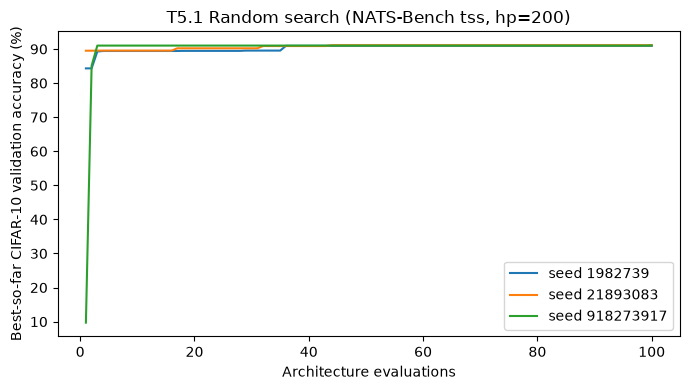

In [ ]:
def random_search(seed, budget=BUDGET):
    rng = random.Random(seed)
    archs, accs = [], []

    for _ in range(budget):
        arch = sample_arch(rng)
        archs.append(arch)
        accs.append(evaluate(arch))

    return {"archs": archs, "accs": accs, "best_so_far": np.maximum.accumulate(accs).tolist()}


rs = {}
for seed in SEEDS:
    rs[seed] = random_search(seed)
    assert len(rs[seed]["accs"]) == BUDGET
    b = int(np.argmax(rs[seed]["accs"]))
    print(f"seed {seed}: best val acc {rs[seed]['best_so_far'][-1]:.2f}% at evaluation {b + 1} | {rs[seed]['archs'][b]} {decode(rs[seed]['archs'][b])}")

evals = np.arange(1, BUDGET + 1)
plt.figure(figsize=(7, 4))
for seed in SEEDS:
    plt.plot(evals, rs[seed]["best_so_far"], label=f"seed {seed}")
plt.title(f"T5.1 Random search (NATS-Bench tss, hp={HP})")
plt.xlabel("Architecture evaluations")
plt.ylabel("Best-so-far CIFAR-10 validation accuracy (%)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/t5_1_random_search.png", dpi=150)
plt.show()

eval  11 | parent (3, 0, 0, 4, 3, 4) (89.27%) -> child (3, 0, 0, 4, 3, 1) (89.05%) | removed oldest (3, 1, 4, 1, 0, 0) (84.32%) | pop size 10
eval  12 | parent (3, 0, 0, 4, 3, 4) (89.27%) -> child (3, 0, 0, 4, 3, 3) (88.81%) | removed oldest (1, 4, 4, 4, 1, 4) (32.47%) | pop size 10
eval  13 | parent (3, 0, 0, 4, 3, 3) (88.81%) -> child (3, 2, 0, 4, 3, 3) (89.33%) | removed oldest (3, 0, 0, 4, 3, 4) (89.27%) | pop size 10
eval  14 | parent (3, 2, 1, 3, 3, 4) (89.43%) -> child (4, 2, 1, 3, 3, 4) (86.01%) | removed oldest (3, 2, 1, 3, 3, 4) (89.43%) | pop size 10
eval  15 | parent (0, 3, 2, 4, 4, 3) (89.05%) -> child (0, 3, 1, 4, 4, 3) (89.15%) | removed oldest (4, 0, 4, 0, 0, 3) (73.73%) | pop size 10
seed 1982739: evaluations 100 | population sizes during evolution {10} | population best decreased 2 times | best val acc 91.61% at evaluation 91 | (3, 3, 3, 1, 3, 2)

seed 21893083: evaluations 100 | population sizes during evolution {10} | population best decreased 7 times | best val acc

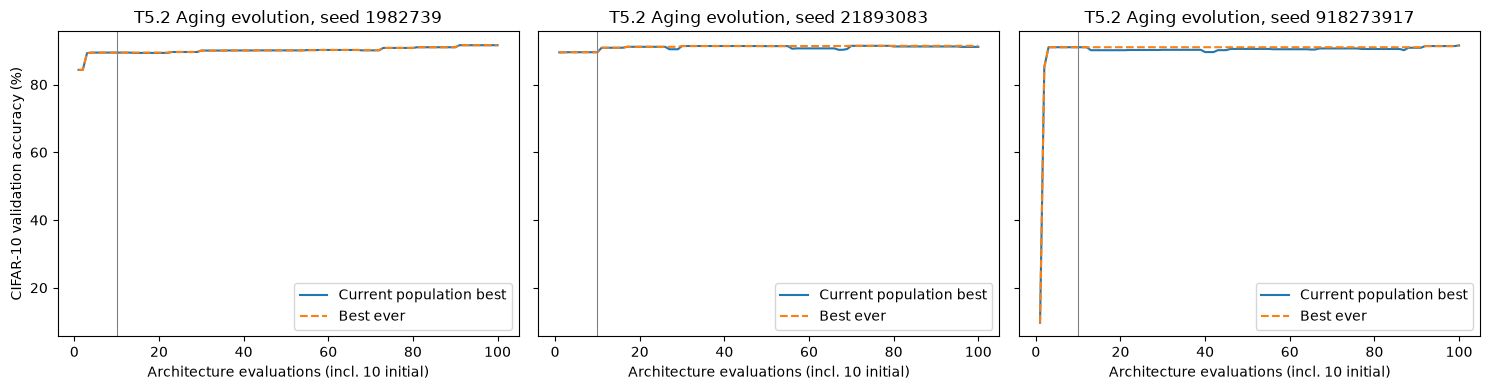

In [ ]:
def aging_evolution(seed, budget=BUDGET, pop_size=10, sample_size=3, trace=0):
    rng = random.Random(seed)
    population = deque()
    archs, accs, pop_best, pop_sizes = [], [], [], []

    def record(arch, acc):
        archs.append(arch)
        accs.append(acc)
        pop_best.append(max(a for _, a in population))
        pop_sizes.append(len(population))

    for _ in range(pop_size):   # initialization counts toward the evaluation budget
        arch = sample_arch(rng)
        acc = evaluate(arch)
        population.append((arch, acc))
        record(arch, acc)

    while len(accs) < budget:
        candidates = rng.sample(list(population), sample_size)   # 3 distinct members
        parent = max(candidates, key=lambda m: m[1])
        child = mutate(parent[0], rng)
        assert sum(a != b for a, b in zip(parent[0], child)) == 1

        acc = evaluate(child)
        population.append((child, acc))
        oldest = population.popleft()
        assert len(population) == pop_size
        record(child, acc)

        if len(accs) - pop_size <= trace:
            print(f"eval {len(accs):3d} | parent {parent[0]} ({parent[1]:.2f}%) -> child {child} ({acc:.2f}%) "
                  f"| removed oldest {oldest[0]} ({oldest[1]:.2f}%) | pop size {len(population)}")

    return {"archs": archs, "accs": accs, "pop_best": pop_best, "best_ever": np.maximum.accumulate(accs).tolist(), "pop_sizes": pop_sizes}


ae = {}
for i, seed in enumerate(SEEDS):
    ae[seed] = aging_evolution(seed, trace=5 if i == 0 else 0)
    r = ae[seed]
    assert len(r["accs"]) == BUDGET
    drops = sum(b < a for a, b in zip(r["pop_best"][9:], r["pop_best"][10:]))
    b = int(np.argmax(r["accs"]))
    print(f"seed {seed}: evaluations {len(r['accs'])} | population sizes during evolution {set(r['pop_sizes'][10:])} "
          f"| population best decreased {drops} times | best val acc {r['best_ever'][-1]:.2f}% at evaluation {b + 1} | {r['archs'][b]}\n")

fig, axes = plt.subplots(1, len(SEEDS), figsize=(15, 4), sharey=True)
for ax, seed in zip(axes, SEEDS):
    ax.plot(evals, ae[seed]["pop_best"], label="Current population best")
    ax.plot(evals, ae[seed]["best_ever"], linestyle="--", label="Best ever")
    ax.axvline(10, color="gray", linewidth=0.8)
    ax.set(title=f"T5.2 Aging evolution, seed {seed}", xlabel="Architecture evaluations (incl. 10 initial)")
    ax.legend()
axes[0].set_ylabel("CIFAR-10 validation accuracy (%)")
plt.tight_layout()
plt.savefig("figures/t5_2_aging_evolution.png", dpi=150)
plt.show()

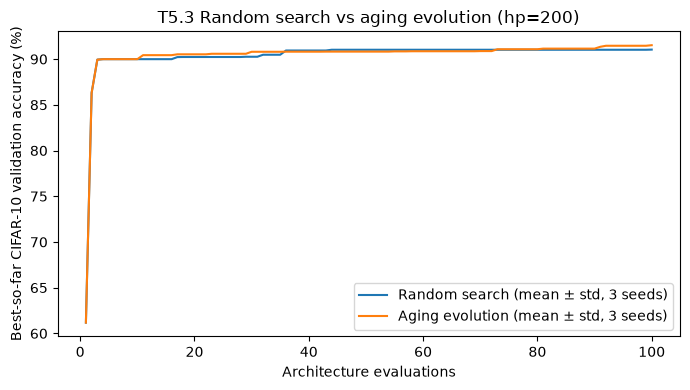

| Method | Seed 1982739 (%) | Seed 21893083 (%) | Seed 918273917 (%) | Best (%) | Mean (%) | Std, ddof=1 (%) |
|---|---|---|---|---|---|---|
| Random search | 90.93 | 91.12 | 91.06 | 91.12 | 91.04 | 0.10 |
| Aging evolution | 91.61 | 91.42 | 91.53 | 91.61 | 91.52 | 0.10 |
evals to reach final best | Random search seed 1982739: 36
evals to reach final best | Random search seed 21893083: 44
evals to reach final best | Random search seed 918273917: 100
evals to reach final best | Aging evolution seed 1982739: 91
evals to reach final best | Aging evolution seed 21893083: 70
evals to reach final best | Aging evolution seed 918273917: 100


In [ ]:
curves = {"Random search": np.array([rs[s]["best_so_far"] for s in SEEDS]),
          "Aging evolution": np.array([ae[s]["best_ever"] for s in SEEDS])}

plt.figure(figsize=(7, 4))
for name, c in curves.items():
    m, sd = c.mean(0), c.std(0, ddof=1)
    line, = plt.plot(evals, m, label=f"{name} (mean ± std, 3 seeds)")
    # plt.fill_between(evals, m - sd, m + sd, alpha=0.2, color=line.get_color())
plt.title(f"T5.3 Random search vs aging evolution (hp={HP})")
plt.xlabel("Architecture evaluations")
plt.ylabel("Best-so-far CIFAR-10 validation accuracy (%)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/t5_3_comparison.png", dpi=150)
plt.show()

summary = {}
print("| Method | " + " | ".join(f"Seed {s} (%)" for s in SEEDS) + " | Best (%) | Mean (%) | Std, ddof=1 (%) |")
print("|---|" + "---|" * (len(SEEDS) + 3))
for name, c in curves.items():
    final = c[:, -1]
    summary[name] = {"per_seed": dict(zip(SEEDS, final.tolist())), "best": final.max(), "mean": final.mean(), "std": final.std(ddof=1)}
    print(f"| {name} | " + " | ".join(f"{a:.2f}" for a in final) + f" | {final.max():.2f} | {final.mean():.2f} | {final.std(ddof=1):.2f} |")

for name, runs in [("Random search", rs), ("Aging evolution", ae)]:
    for seed in SEEDS:
        b = int(np.argmax(runs[seed]["accs"]))
        print(f"evals to reach final best | {name} seed {seed}: {b + 1}")

with open("results/t5.json", "w") as f:
    json.dump({"metric": "cifar10-valid valid-accuracy, is_random=False", "hp": HP, "budget": BUDGET, "seeds": SEEDS,
               "summary": summary, "random_search": rs, "aging_evolution": ae}, f, indent=1)

### Task 4

In [ ]:
import copy, json, os, random, time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

import data, utils  

OP_NAMES = ["conv3x3", "conv5x5", "dwsep3x3", "identity"]

def _wrap(layer, num_groups):
    return nn.Sequential(
        layer, nn.GroupNorm(num_groups, num_channels=16), nn.ReLU()
    )

class SuperNet(nn.Module):
    def __init__(self, num_searchable, rng, num_groups=4):
        super().__init__()
        self.stem = _wrap(nn.Conv2d(3, 16, 3, padding=1), num_groups)
        self.num_groups = num_groups
        self.blocks = nn.ModuleList([nn.ModuleList([
                        _wrap(nn.Conv2d(16, 16, 3, padding=1), self.num_groups),
                        _wrap(nn.Conv2d(16, 16, 5, padding=2), self.num_groups),
                        _wrap(nn.Sequential(nn.Conv2d(16, 16, 3, groups=16, padding=1), nn.Conv2d(16, 16, 1)), self.num_groups),
                        nn.Identity()
                        ])
                       for _ in range(num_searchable)])

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.flatten = nn.Flatten()
        self.linear = nn.Linear(16, 10)
        self.num_searchable = num_searchable
        self.num_ops = len(OP_NAMES)
        self.rng = rng

    def get_path(self, indices):
        assert len(indices) == self.num_searchable
        model = []
        model.append(self.stem)
        for i in range(self.num_searchable):
            model.append(self.blocks[i][indices[i]])
        model.append(self.global_pool)
        model.append(self.flatten)
        model.append(self.linear)

        return nn.Sequential(*model)

    def sample_indices(self):
        return tuple(self.rng.randint(0, self.num_ops - 1) for _ in range(self.num_searchable))

    def random_path(self):
        indices = self.sample_indices()
        return self.get_path(indices), indices

    def extract(self, indices):
        return copy.deepcopy(self.get_path(indices))

    def forward(self, x, indices):
        return self.get_path(indices)(x)


def active_params(supernet, indices):
    prefixes = ("stem.", "linear.") + tuple(f"blocks.{b}.{i}." for b, i in enumerate(indices))
    return {n for n, _ in supernet.named_parameters() if n.startswith(prefixes)}

def n_params(module):
    return sum(p.numel() for p in module.parameters())

In [ ]:
T4_SEED, T4_LR, T4_EPOCHS = 88753, 0.1, 5

torch.manual_seed(T4_SEED)
rng = random.Random(T4_SEED)
superNet = SuperNet(num_searchable=4, rng=rng)

train4, val4 = data.get_cifar_loaders(".", n_train=5000, n_val=1000, batch_size=32, seed=T4_SEED)

print(f"train: {len(train4.dataset)} | val: {len(val4.dataset)} | search space: 4^4 = {superNet.num_ops ** superNet.num_searchable}")

train: 5000 | val: 1000 | search space: 4^4 = 256


In [ ]:
x, _ = next(iter(val4))
(net_a, path_a), (net_b, path_b) = superNet.random_path(), superNet.random_path()

with torch.no_grad():
    h = superNet.stem(x)
    # for ops in superNet.blocks:
    #     assert all(op(h).shape == h.shape for op in ops)   # every op keeps B x 16 x 32 x 32

    for net, path in [(net_a, path_a), (net_b, path_b)]:
        print(path, [OP_NAMES[i] for i in path], "| params:", n_params(net), "| output:", tuple(net(x).shape))

# print("params per op:", {name: n_params(op) for name, op in zip(OP_NAMES, superNet.blocks[0])})
# assert all(n_params(superNet.blocks[b][3]) == 0 for b in range(superNet.num_searchable))   # identity has no parameters

# # stem and linear head are always shared; a block is shared only if both paths pick the same op
# for b, (i, j) in enumerate(zip(path_a, path_b)):
#     print(f"block {b}: {OP_NAMES[i]} / {OP_NAMES[j]} ->", "shared" if i == j else "not shared")
# shared = active_params(superNet, path_a) & active_params(superNet, path_b)
# named = dict(superNet.named_parameters())
# print("shared tensors:", sorted(shared), "| shared params:", sum(named[n].numel() for n in shared))

# # extraction: standalone copy with identical outputs
# sub = superNet.extract(path_a)
# with torch.no_grad():
#     assert torch.allclose(sub(x), net_a(x))
# print("extracted subnetwork matches the supernet path")

(1, 0, 2, 0) ['conv5x5', 'conv3x3', 'dwsep3x3', 'conv3x3'] | params: 12266 | output: (32, 10)
(2, 1, 0, 1) ['dwsep3x3', 'conv5x5', 'conv3x3', 'conv5x5'] | params: 16362 | output: (32, 10)


In [ ]:


opt = torch.optim.SGD(superNet.parameters(), lr=T4_LR, momentum=0.9)
val_paths = [superNet.sample_indices() for _ in range(4)]   # fixed paths for the validation curve

counts = np.zeros((superNet.num_searchable, superNet.num_ops), dtype=int)   

hist = {"train_loss": [], "val_top1": []}
inactive_changed, train_time = 0, 0.0

for epoch in range(T4_EPOCHS):
    superNet.train()
    losses, start = [], time.time()

    for x, y in tqdm(train4, desc=f"epoch {epoch}"):
        path, indices = superNet.random_path()
        loss = F.cross_entropy(path(x), y)
        opt.zero_grad()   
        loss.backward()

        # active = active_params(superNet, indices)
        # before = {n: p.detach().clone() for n, p in superNet.named_parameters() if n not in active}
        opt.step()
        # inactive_changed += sum(not torch.equal(p, before[n]) for n, p in superNet.named_parameters() if n in before)

        counts[np.arange(superNet.num_searchable), list(indices)] += 1
        losses.append(loss.item())

    train_time += time.time() - start
    hist["train_loss"].append(float(np.mean(losses)))
    hist["val_top1"].append(float(np.mean([utils.evaluate(superNet.get_path(p), val4)["top1"] for p in val_paths])))
    print(f"epoch {epoch} | train loss {hist['train_loss'][-1]:.3f} | val top-1 {hist['val_top1'][-1]:.3f}")

torch.save(superNet.state_dict(), "checkpoints/supernet.pt")

epoch 0: 100%|██████████| 157/157 [00:03<00:00, 51.82it/s]


epoch 0 | train loss 2.347 | val top-1 0.100


epoch 1: 100%|██████████| 157/157 [00:03<00:00, 44.30it/s]


epoch 1 | train loss 2.318 | val top-1 0.098


epoch 2: 100%|██████████| 157/157 [00:08<00:00, 18.21it/s]


epoch 2 | train loss 2.319 | val top-1 0.100


epoch 3: 100%|██████████| 157/157 [00:07<00:00, 19.93it/s]


epoch 3 | train loss 2.311 | val top-1 0.100


epoch 4: 100%|██████████| 157/157 [00:10<00:00, 15.68it/s]


epoch 4 | train loss 2.312 | val top-1 0.101


updates: 785 | training time: 33 s | inactive params changed: 0
sampling counts (rows = blocks, columns = ['conv3x3', 'conv5x5', 'dwsep3x3', 'identity'] )
 [[215 184 189 197]
 [210 198 199 178]
 [187 205 185 208]
 [194 194 208 189]]


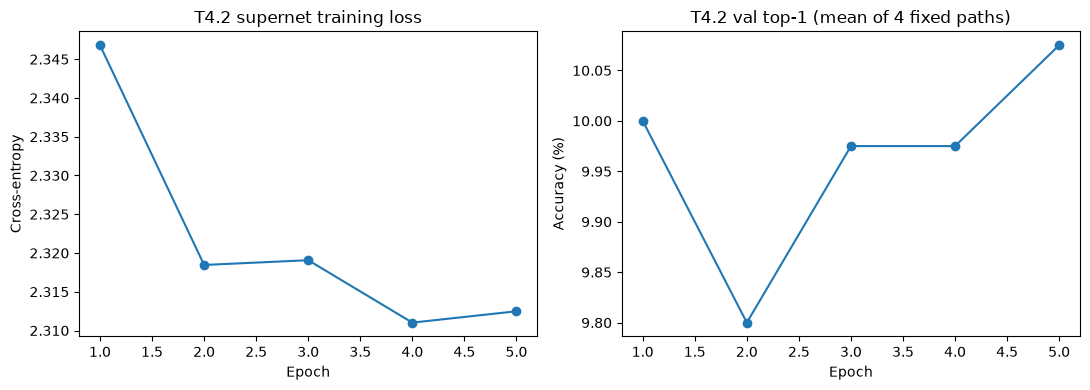

In [ ]:
print(f"updates: {T4_EPOCHS * len(train4)} | training time: {train_time:.0f} s | inactive params changed: {inactive_changed}")
print("sampling counts (rows = blocks, columns =", OP_NAMES, ")\n", counts)

ep = range(1, T4_EPOCHS + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, hist["train_loss"], marker="o")
ax[0].set(title="T4.2 supernet training loss", xlabel="Epoch", ylabel="Cross-entropy")
ax[1].plot(ep, [100 * a for a in hist["val_top1"]], marker="o")
ax[1].set(title="T4.2 val top-1 (mean of 4 fixed paths)", xlabel="Epoch", ylabel="Accuracy (%)")
plt.tight_layout()
plt.savefig("figures/t4_2_supernet.png", dpi=150)
plt.show()

In [ ]:
# T4.3: 12 distinct subnetworks, each adapted independently from the same checkpoint
subnets = []
while len(subnets) < 12:
    _, indices = superNet.random_path()
    if indices not in subnets:
        subnets.append(indices)

def adapt(indices):
    supernet = SuperNet(num_searchable=4, rng=random.Random(T4_SEED))
    supernet.load_state_dict(torch.load("checkpoints/supernet.pt"))
    model = supernet.extract(indices)
    opt = torch.optim.SGD(model.parameters(), lr=T4_LR, momentum=0.9)
    torch.manual_seed(T4_SEED)   # same minibatches for every subnetwork
    batches = iter(train4)
    accs = [utils.evaluate(model, val4)["top1"]]   # inherited weights, 0 updates

    for step in range(1, 31):
        model.train()
        x, y = next(batches)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step in (10, 30):   # the 30-step result continues from step 10
            accs.append(utils.evaluate(model, val4)["top1"])
    return accs

accs = np.array([adapt(p) for p in tqdm(subnets)])   # rows = subnetworks, columns = 0 / 10 / 30 updates

100%|██████████| 12/12 [00:51<00:00,  4.27s/it]


| Path | Ops | Val acc 0 / 10 / 30 updates (%) | Rank 0 / 10 / 30 |
|---|---|---|---|
| (0, 1, 1, 3) | conv3x3, conv5x5, conv5x5, identity | 10.0 / 10.0 / 11.3 | 8 / 10 / 10 |
| (0, 3, 1, 3) | conv3x3, identity, conv5x5, identity | 10.0 / 10.2 / 12.6 | 6 / 9 / 5 |
| (1, 2, 2, 0) | conv5x5, dwsep3x3, dwsep3x3, conv3x3 | 10.6 / 10.5 / 11.9 | 2 / 8 / 8 |
| (3, 3, 3, 2) | identity, identity, identity, dwsep3x3 | 10.0 / 12.1 / 13.8 | 7 / 3 / 3 |
| (2, 1, 0, 3) | dwsep3x3, conv5x5, conv3x3, identity | 10.5 / 13.1 / 12.2 | 4 / 1 / 7 |
| (1, 2, 3, 1) | conv5x5, dwsep3x3, identity, conv5x5 | 10.0 / 13.0 / 11.6 | 10 / 2 / 9 |
| (2, 0, 3, 0) | dwsep3x3, conv3x3, identity, conv3x3 | 10.9 / 11.1 / 14.0 | 1 / 5 / 2 |
| (2, 0, 3, 2) | dwsep3x3, conv3x3, identity, dwsep3x3 | 9.7 / 10.9 / 10.8 | 12 / 6 / 12 |
| (1, 0, 1, 3) | conv5x5, conv3x3, conv5x5, identity | 10.0 / 10.0 / 12.5 | 9 / 11 / 6 |
| (2, 1, 3, 0) | dwsep3x3, conv5x5, identity, conv3x3 | 10.4 / 10.6 / 12.7 | 5 / 7 / 4 |
| (3, 2, 0, 1) | i

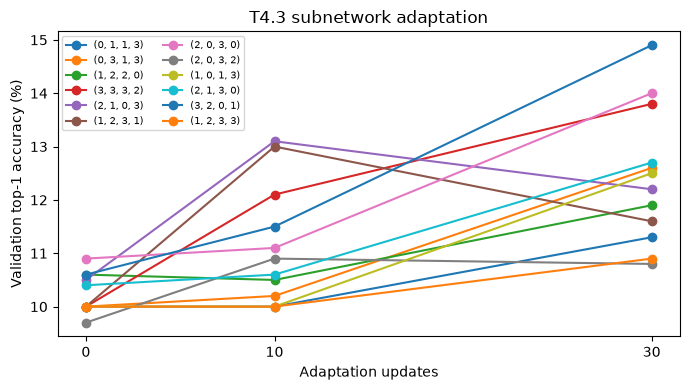

In [ ]:
def kendall_tau(a, b):   # tau-b: tied pairs count as neither concordant nor discordant
    pairs = [(np.sign(a[i] - a[j]), np.sign(b[i] - b[j])) for i in range(len(a)) for j in range(i + 1, len(a))]
    n_a = sum(sa != 0 for sa, _ in pairs)
    n_b = sum(sb != 0 for _, sb in pairs)
    return sum(sa * sb for sa, sb in pairs) / np.sqrt(n_a * n_b)

ranks = (-accs).argsort(0).argsort(0) + 1   # 1 = best, per stage

print("| Path | Ops | Val acc 0 / 10 / 30 updates (%) | Rank 0 / 10 / 30 |")
print("|---|---|---|---|")
for p, a, r in zip(subnets, accs, ranks):
    print(f"| {p} | {', '.join(OP_NAMES[i] for i in p)} | {' / '.join(f'{100 * v:.1f}' for v in a)} | {' / '.join(map(str, r))} |")

taus = {"inherited vs 10": kendall_tau(accs[:, 0], accs[:, 1]), "inherited vs 30": kendall_tau(accs[:, 0], accs[:, 2])}
print("Kendall tau:", {k: round(v, 3) for k, v in taus.items()})
print("best inherited:", subnets[accs[:, 0].argmax()], "| best after 30 updates:", subnets[accs[:, 2].argmax()])

plt.figure(figsize=(7, 4))
for p, a in zip(subnets, accs):
    plt.plot([0, 10, 30], 100 * a, marker="o", label=str(p))
plt.title("T4.3 subnetwork adaptation")
plt.xlabel("Adaptation updates")
plt.ylabel("Validation top-1 accuracy (%)")
plt.xticks([0, 10, 30])
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("figures/t4_3_adaptation.png", dpi=150)
plt.show()

In [ ]:
# T4.4: best after 30 updates vs a random different subnetwork, both trained from scratch
best = subnets[accs[:, 2].argmax()]
other = random.Random(T4_SEED).choice([p for p in subnets if p != best])
scratch = {}

for indices in [best, other]:
    torch.manual_seed(T4_SEED)   # same init and data order for both
    model = SuperNet(num_searchable=4, rng=random.Random(T4_SEED)).extract(indices)
    opt = torch.optim.SGD(model.parameters(), lr=T4_LR, momentum=0.9)

    def loss_fn(x, y):
        logits = model(x)
        return F.cross_entropy(logits, y), logits, {}

    scratch[indices] = max(utils.train(model, loss_fn, opt, train4, val4, T4_EPOCHS)["val_top1"])

for name, indices in [("best after 30", best), ("random", other)]:
    a = accs[subnets.index(indices)]
    print(f"{name} {indices}: inherited {100 * a[0]:.1f} | adapted 10 {100 * a[1]:.1f} | adapted 30 {100 * a[2]:.1f} "
          f"| from scratch {100 * scratch[indices]:.1f} (% val top-1)")

with open("results/t4.json", "w") as f:
    json.dump({"seed": T4_SEED, "lr": T4_LR, "epochs": T4_EPOCHS, "train_time_s": train_time,
               "inactive_changed": inactive_changed, "counts": counts.tolist(), "supernet_history": hist,
               "subnets": subnets, "accs_0_10_30": accs.tolist(), "kendall_tau": taus,
               "scratch": {str(p): v for p, v in scratch.items()}}, f, indent=1)

Epoch 0/4: 100%|██████████| 157/157 [00:06<00:00, 24.10it/s]


Epoch 0/4 | train loss 2.1966 | val loss 2.1010 top1 0.1910 top5 0.6950


Epoch 1/4: 100%|██████████| 157/157 [00:06<00:00, 25.98it/s]


Epoch 1/4 | train loss 2.0882 | val loss 2.0465 top1 0.1990 top5 0.7650


Epoch 2/4: 100%|██████████| 157/157 [00:06<00:00, 25.31it/s]


Epoch 2/4 | train loss 2.0319 | val loss 1.9987 top1 0.2310 top5 0.7940


... (10 outputs left out)

Epoch 3/4: 100%|██████████| 157/157 [00:09<00:00, 16.00it/s]


Epoch 3/4 | train loss 2.0820 | val loss 2.0736 top1 0.2080 top5 0.7630


Epoch 4/4: 100%|██████████| 157/157 [00:10<00:00, 15.06it/s]


Epoch 4/4 | train loss 2.0462 | val loss 2.0242 top1 0.1990 top5 0.7790
best after 30 (3, 2, 0, 1): inherited 10.6 | adapted 10 11.5 | adapted 30 14.9 | from scratch 24.9 (% val top-1)
random (1, 2, 2, 0): inherited 10.6 | adapted 10 10.5 | adapted 30 11.9 | from scratch 20.8 (% val top-1)


### Task 3

In [2]:
import copy, json, os, random, time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

import data, utils

OP_NAMES = ["none", "skip", "conv1x1", "conv3x3", "avgpool3x3"]
EDGES = [(i, j) for j in range(1, 4) for i in range(j)]   # (0,1) (0,2) (1,2) (0,3) (1,3) (2,3)

class Zero(nn.Module):   # "none" op
    def forward(self, x):
        return x * 0.0

def conv_op(C, k):
    return nn.Sequential(nn.ReLU(), nn.Conv2d(C, C, k, padding=k // 2, bias=False), nn.BatchNorm2d(C, affine=False))

class Edge(nn.Module):  
    def __init__(self, C=16):
        super().__init__()
        self.ops = nn.ModuleList([Zero(), nn.Identity(), conv_op(C, 1), conv_op(C, 3),
                                  nn.AvgPool2d(3, stride=1, padding=1, count_include_pad=False)])

    def forward(self, x, p):
        return sum(w * op(x) for w, op in zip(p, self.ops))

class Cell(nn.Module): 
    def __init__(self, C=16):
        super().__init__()
        self.edges = nn.ModuleList([Edge(C) for _ in EDGES])

    def forward(self, x, probs):   # probs: 6 x 5
        states = [x]
        for j in range(1, 4):
            states.append(sum(self.edges[e](states[i], probs[e]) for e, (i, jj) in enumerate(EDGES) if jj == j))
        return states[3]

class Network(nn.Module):
    def __init__(self, C=16):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, C, 3, padding=1, bias=False), nn.BatchNorm2d(C))
        self.cells = nn.ModuleList([Cell(C), Cell(C)])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(C, 10))
        self.alpha = nn.Parameter(1e-3 * torch.randn(len(EDGES), len(OP_NAMES)))   # shared by both cells

    def probs(self):
        return F.softmax(self.alpha, dim=-1)

    def forward(self, x):
        p = self.probs()
        x = self.stem(x)
        for cell in self.cells:
            x = cell(x, p)
        return self.head(x)

    def weights(self):   # everything except alpha, for the w optimizer in T3.2
        return [p for n, p in self.named_parameters() if n != "alpha"]

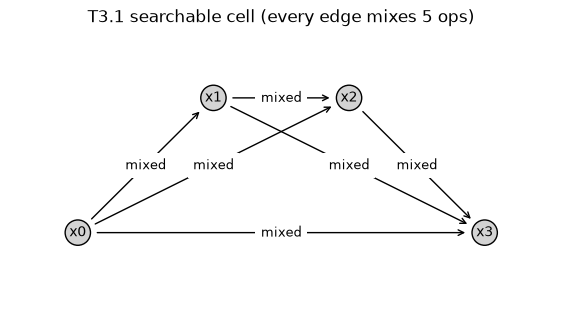

train: 5000 | val: 1000
edges: [(0, 1), (0, 2), (1, 2), (0, 3), (1, 3), (2, 3)] | alpha shape: (6, 5) (shared by both cells)


In [3]:
T3_SEED, T3_EPOCHS, T3_BATCH = 0, 3, 64

torch.manual_seed(T3_SEED)
train3, val3 = data.get_cifar_loaders(".", n_train=5000, n_val=1000, batch_size=T3_BATCH, seed=T3_SEED)
net = Network()

def draw_cell(genotype, title, path):   # genotype: list of (input node, output node, op name)
    pos = {0: (0, 0), 1: (1, 1), 2: (2, 1), 3: (3, 0)}
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for i, j, op in genotype:
        (x0, y0), (x1, y1) = pos[i], pos[j]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", shrinkA=14, shrinkB=14))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, op, ha="center", va="center", fontsize=9, bbox=dict(fc="white", ec="none"))
    for n, (x, y) in pos.items():
        ax.text(x, y, f"x{n}", ha="center", va="center", bbox=dict(boxstyle="circle", fc="lightgray"))
    ax.set(xlim=(-0.5, 3.5), ylim=(-0.5, 1.5), title=title)
    ax.axis("off")
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

draw_cell([(i, j, "mixed") for i, j in EDGES], "T3.1 searchable cell (every edge mixes 5 ops)", "figures/t3_1_cell.png")
print("train:", len(train3.dataset), "| val:", len(val3.dataset))
print("edges:", EDGES, "| alpha shape:", tuple(net.alpha.shape), "(shared by both cells)")

In [4]:
# T3.1 b) shapes, forward/backward, probabilities, effect of alpha
x, y = next(iter(train3))
net.eval()   # eval mode for the checks, so BatchNorm running stats are not changed

with torch.no_grad():
    h = net.stem(x)
    print("stem:", tuple(h.shape))
    for name, op in zip(OP_NAMES, net.cells[0].edges[0].ops):
        assert op(h).shape == h.shape   # every op preserves B x 16 x 32 x 32
        print(f"  op {name}: {tuple(op(h).shape)}")
    for k, cell in enumerate(net.cells):
        h = cell(h, net.probs())
        print(f"cell {k}: {tuple(h.shape)}")

out = net(x)
loss = F.cross_entropy(out, y)
loss.backward()
print("output:", tuple(out.shape), "| loss:", round(loss.item(), 3))
print("alpha has grad:", net.alpha.grad.abs().sum().item() > 0,
      "| all op weights have grad:", all(p.grad is not None for p in net.weights()))
net.zero_grad()

print("probabilities sum to 1 on every edge:", torch.allclose(net.probs().sum(1), torch.ones(len(EDGES))))

# change alpha while the operation weights stay fixed: the mixed outputs must change
with torch.no_grad():
    w_before = [p.clone() for p in net.weights()]
    h = net.stem(x)
    edge1, out1 = net.cells[0].edges[0](h, net.probs()[0]), net(x)
    alpha0 = net.alpha.clone()
    net.alpha.add_(torch.randn_like(net.alpha))
    edge2, out2 = net.cells[0].edges[0](h, net.probs()[0]), net(x)
    net.alpha.copy_(alpha0)

print("weights unchanged:", all(torch.equal(p, q) for p, q in zip(net.weights(), w_before)),
      "| edge output changed:", not torch.allclose(edge1, edge2),
      "| network output changed:", not torch.allclose(out1, out2))

stem: (64, 16, 32, 32)
  op none: (64, 16, 32, 32)
  op skip: (64, 16, 32, 32)
  op conv1x1: (64, 16, 32, 32)
  op conv3x3: (64, 16, 32, 32)
  op avgpool3x3: (64, 16, 32, 32)
cell 0: (64, 16, 32, 32)
cell 1: (64, 16, 32, 32)
output: (64, 10) | loss: 2.351
alpha has grad: True | all op weights have grad: True
probabilities sum to 1 on every edge: True
weights unchanged: True | edge output changed: True | network output changed: True


In [5]:
# T3.2: separate optimizers; w on training data, alpha on validation data (first-order DARTS)
def make_optimizers(net):
    w_opt = torch.optim.SGD(net.weights(), lr=0.025, momentum=0.9, weight_decay=3e-4)   # DARTS defaults
    a_opt = torch.optim.Adam([net.alpha], lr=3e-3, betas=(0.5, 0.999), weight_decay=1e-3)   # DARTS uses 3e-4; raised for 3 short epochs
    return w_opt, a_opt

def arch_step(net, a_opt, xv, yv):   # w is not in a_opt, so it stays fixed
    a_opt.zero_grad()
    loss = F.cross_entropy(net(xv), yv)
    loss.backward()
    a_opt.step()

def weight_step(net, w_opt, x, y):   # alpha is not in w_opt, so it stays fixed
    w_opt.zero_grad()
    logits = net(x)
    loss = F.cross_entropy(logits, y)
    loss.backward()
    w_opt.step()
    return loss.item(), (logits.argmax(1) == y).float().mean().item()

def forever(loader):
    while True:
        yield from loader


# verify on a throwaway copy that each optimizer updates only its own parameters
tmp = copy.deepcopy(net)
w_opt_t, a_opt_t = make_optimizers(tmp)
x, y = next(iter(train3))
xv, yv = next(iter(val3))

w_ids = {id(p) for p in w_opt_t.param_groups[0]["params"]}
print("alpha not in w optimizer:", id(tmp.alpha) not in w_ids,
      "| optimizers cover all params:", len(w_ids) + 1 == len(list(tmp.parameters())))

w0, a0 = [p.detach().clone() for p in tmp.weights()], tmp.alpha.detach().clone()
arch_step(tmp, a_opt_t, xv, yv)
print("alpha step | alpha changed:", not torch.equal(tmp.alpha, a0),
      "| w unchanged:", all(torch.equal(p, q) for p, q in zip(tmp.weights(), w0)))

w1, a1 = [p.detach().clone() for p in tmp.weights()], tmp.alpha.detach().clone()
weight_step(tmp, w_opt_t, x, y)
print("w step | w changed:", any(not torch.equal(p, q) for p, q in zip(tmp.weights(), w1)),
      "| alpha unchanged:", torch.equal(tmp.alpha, a1))

alpha not in w optimizer: True | optimizers cover all params: True
alpha step | alpha changed: True | w unchanged: True
w step | w changed: True | alpha unchanged: True


In [6]:
# T3.2 b) search for 3 epochs: each training batch is paired with a validation batch
torch.manual_seed(T3_SEED)
net = Network()
w_opt, a_opt = make_optimizers(net)
val_batches = forever(val3)

hist = defaultdict(list)
probs_hist = [net.probs().detach().clone()]   # one entry per alpha update
start = time.time()

for epoch in range(T3_EPOCHS):
    net.train()
    losses, accs = [], []

    for x, y in tqdm(train3, desc=f"epoch {epoch}"):
        xv, yv = next(val_batches)
        arch_step(net, a_opt, xv, yv)
        loss, acc = weight_step(net, w_opt, x, y)
        losses.append(loss)
        accs.append(acc)
        probs_hist.append(net.probs().detach().clone())

    val = utils.evaluate(net, val3)
    hist["train_loss"].append(float(np.mean(losses)))
    hist["train_top1"].append(float(np.mean(accs)))
    hist["val_loss"].append(val["loss"])
    hist["val_top1"].append(val["top1"])
    print(f"epoch {epoch} | train loss {hist['train_loss'][-1]:.3f} top1 {hist['train_top1'][-1]:.3f} "
          f"| val loss {val['loss']:.3f} top1 {val['top1']:.3f}")

search_time = time.time() - start
updates = T3_EPOCHS * len(train3)
torch.save(net.state_dict(), "checkpoints/darts_supernet.pt")

epoch 0: 100%|██████████| 79/79 [01:37<00:00,  1.24s/it]


epoch 0 | train loss 2.096 top1 0.204 | val loss 2.015 top1 0.229


epoch 1: 100%|██████████| 79/79 [02:02<00:00,  1.55s/it]


epoch 1 | train loss 1.916 top1 0.271 | val loss 1.868 top1 0.302


epoch 2: 100%|██████████| 79/79 [01:49<00:00,  1.39s/it]


epoch 2 | train loss 1.837 top1 0.300 | val loss 1.868 top1 0.287


search: 3 epochs | 237 w updates + 237 alpha updates | 340 s


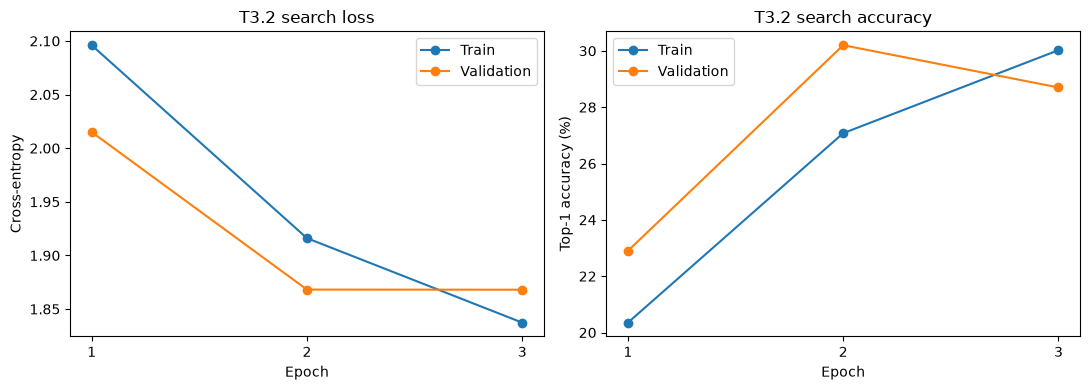

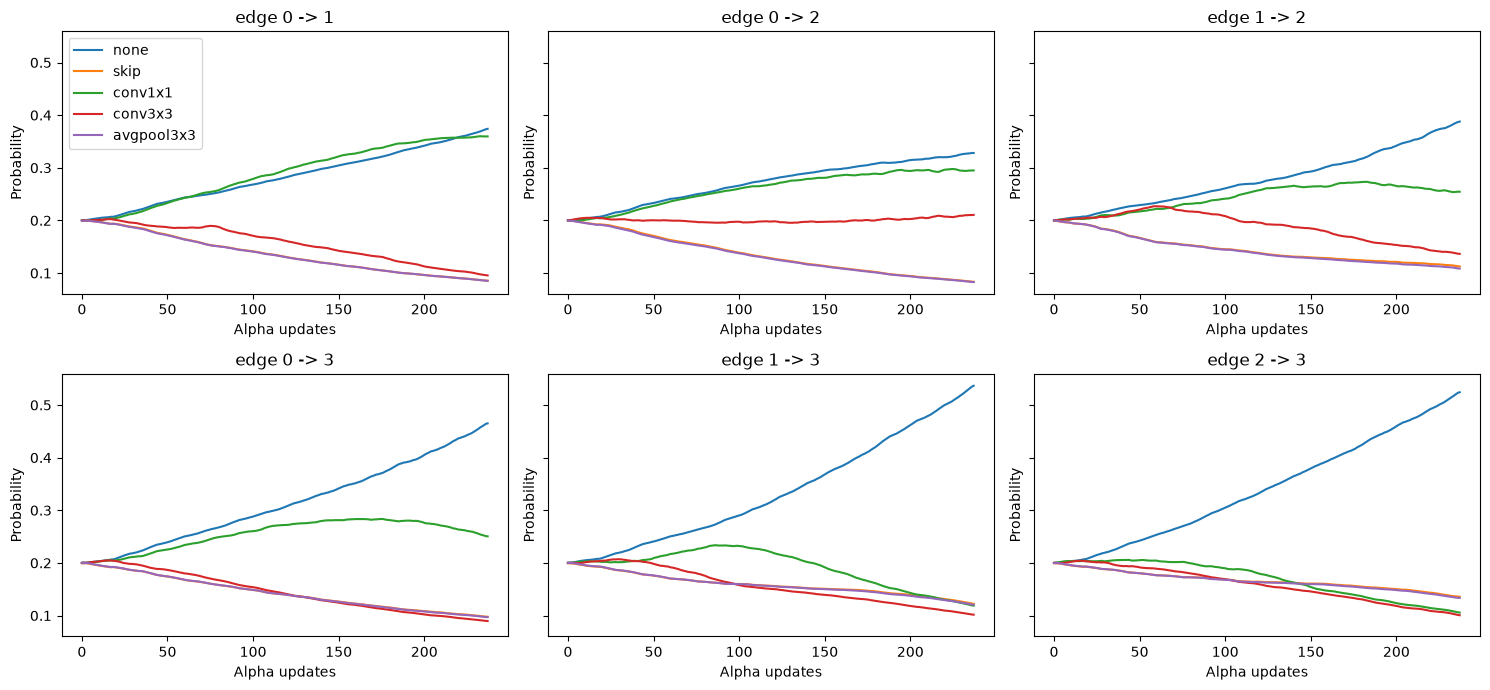

final probabilities (rows = edges [(0, 1), (0, 2), (1, 2), (0, 3), (1, 3), (2, 3)] , columns = ['none', 'skip', 'conv1x1', 'conv3x3', 'avgpool3x3'] )
 [[0.374 0.086 0.36  0.096 0.085]
 [0.328 0.083 0.295 0.211 0.083]
 [0.388 0.113 0.254 0.137 0.109]
 [0.465 0.098 0.251 0.09  0.097]
 [0.537 0.122 0.119 0.102 0.12 ]
 [0.524 0.136 0.106 0.101 0.134]]
mean change in probability per op: {'none': 0.236, 'skip': -0.0936, 'conv1x1': 0.0307, 'conv3x3': -0.0776, 'avgpool3x3': -0.0955}


In [11]:
print(f"search: {T3_EPOCHS} epochs | {updates} w updates + {updates} alpha updates | {search_time:.0f} s")

ep = range(1, T3_EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, hist["train_loss"], marker="o", label="Train")
ax[0].plot(ep, hist["val_loss"], marker="o", label="Validation")
ax[0].set(title="T3.2 search loss", xlabel="Epoch", ylabel="Cross-entropy")
ax[1].plot(ep, [100 * a for a in hist["train_top1"]], marker="o", label="Train")
ax[1].plot(ep, [100 * a for a in hist["val_top1"]], marker="o", label="Validation")
ax[1].set(title="T3.2 search accuracy", xlabel="Epoch", ylabel="Top-1 accuracy (%)")
for a in ax:
    a.set_xticks(list(ep))
    a.legend()
plt.tight_layout()
plt.savefig("figures/t3_2_curves.png", dpi=150)
plt.show()

P = torch.stack(probs_hist).numpy()   # steps x edges x ops
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for e, a in enumerate(axes.flat):
    for o, name in enumerate(OP_NAMES):
        a.plot(P[:, e, o], label=name)
    a.set(title=f"edge {EDGES[e][0]} -> {EDGES[e][1]}", xlabel="Alpha updates", ylabel="Probability")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("figures/t3_2_probs.png", dpi=150)
plt.show()

print("final probabilities (rows = edges", EDGES, ", columns =", OP_NAMES, ")\n", P[-1].round(3))
print("mean change in probability per op:", {n: round(float(d), 4) for n, d in zip(OP_NAMES, (P[-1] - P[0]).mean(0))})

genotype: [(0, 1, 'conv1x1'), (0, 2, 'conv1x1'), (1, 2, 'conv1x1'), (0, 3, 'conv1x1'), (2, 3, 'skip')]


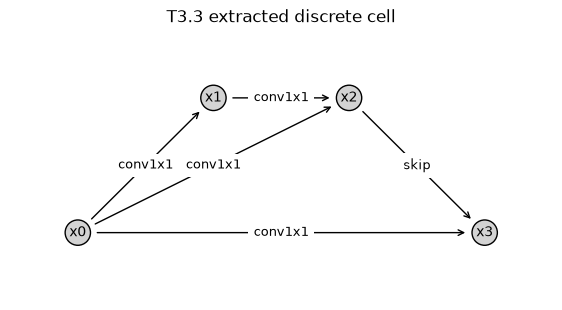

In [12]:
# T3.3 a) keep the 2 strongest incoming edges per node; rank and choose by the best non-"none" op
probs = net.probs().detach()
strength = probs[:, 1:].max(1).values   # best non-zero op probability per edge
best_op = probs[:, 1:].argmax(1) + 1    # index into OP_NAMES, never "none"

genotype = []   # architecture encoding: (input node, output node, op)
for j in range(1, 4):
    incoming = [e for e, (i, jj) in enumerate(EDGES) if jj == j]
    keep = sorted(incoming, key=lambda e: -strength[e])[:2]
    genotype += [(EDGES[e][0], j, OP_NAMES[best_op[e]]) for e in sorted(keep)]

assert len(genotype) == 5
print("genotype:", genotype)
draw_cell(genotype, "T3.3 extracted discrete cell", "figures/t3_3_discrete_cell.png")


class DiscreteNetwork(nn.Module):   # keeps only the chosen op on each retained edge, with that op's weights
    def __init__(self, supernet, genotype):
        super().__init__()
        supernet = copy.deepcopy(supernet)
        self.genotype = genotype
        self.stem, self.head = supernet.stem, supernet.head
        self.cells = nn.ModuleList([
            nn.ModuleList([cell.edges[EDGES.index((i, j))].ops[OP_NAMES.index(op)] for i, j, op in genotype])
            for cell in supernet.cells])

    def forward(self, x):
        x = self.stem(x)
        for ops in self.cells:
            states = [x]
            for j in range(1, 4):
                states.append(sum(op(states[i]) for op, (i, jj, _) in zip(ops, self.genotype) if jj == j))
            x = states[3]
        return self.head(x)

In [13]:
# T3.3 b) continuous supernet vs discrete model, both from the same checkpoint, no fine-tuning
supernet = Network()
supernet.load_state_dict(torch.load("checkpoints/darts_supernet.pt"))
inherited = DiscreteNetwork(supernet, genotype)

# T3.3 c) newly initialized copy of the discrete architecture, trained for 5 epochs
torch.manual_seed(T3_SEED)
scratch = DiscreteNetwork(Network(), genotype)
opt = torch.optim.SGD(scratch.parameters(), lr=0.025, momentum=0.9, weight_decay=3e-4)

def loss_fn(x, y):
    logits = scratch(x)
    return F.cross_entropy(logits, y), logits, {}

hist_scratch = utils.train(scratch, loss_fn, opt, train3, val3, 5, "cpu", "checkpoints/darts_discrete.pt")

Epoch 0/4: 100%|██████████| 79/79 [00:04<00:00, 16.77it/s]


Epoch 0/4 | train loss 2.0303 | val loss 2.0721 top1 0.1960 top5 0.7650


Epoch 1/4: 100%|██████████| 79/79 [00:04<00:00, 16.80it/s]


Epoch 1/4 | train loss 1.8865 | val loss 1.9404 top1 0.2710 top5 0.8210


Epoch 2/4: 100%|██████████| 79/79 [00:05<00:00, 15.53it/s]


Epoch 2/4 | train loss 1.8137 | val loss 1.8917 top1 0.2830 top5 0.8480


Epoch 3/4: 100%|██████████| 79/79 [00:05<00:00, 15.77it/s]


Epoch 3/4 | train loss 1.7681 | val loss 1.8056 top1 0.3210 top5 0.8500


Epoch 4/4: 100%|██████████| 79/79 [00:05<00:00, 14.67it/s]


Epoch 4/4 | train loss 1.7337 | val loss 1.7917 top1 0.3200 top5 0.8600


In [14]:
from efficientp import profile

def size_mb(m):   # parameters + buffers (BatchNorm running stats) in float32
    return sum(t.numel() * t.element_size() for t in list(m.parameters()) + list(m.buffers())) / 1e6

models = {"Continuous supernet": supernet, "Discrete, inherited weights": inherited, "Discrete, trained from scratch (5 epochs)": scratch}
rows = {}
for name, m in models.items():
    prof = profile(m, (1, 3, 32, 32), torch.device("cpu"))
    rows[name] = {**utils.evaluate(m, val3), "params": prof["parameters"], "macs": prof["macs"],
                  "size_mb": size_mb(m), "latency_s": prof["total_latency"]}

print("| Model | Val top-1 (%) | Val loss | Parameters | MACs (M) | Size (MB) | Latency, bs=1 (ms) |")
print("|---|---|---|---|---|---|---|")
for name, r in rows.items():
    print(f"| {name} | {100 * r['top1']:.1f} | {r['loss']:.3f} | {r['params']} | {r['macs'] / 1e6:.2f} "
          f"| {r['size_mb']:.3f} | {1000 * r['latency_s']:.2f} |")

with open("results/t3.json", "w") as f:
    json.dump({"seed": T3_SEED, "batch_size": T3_BATCH, "search_epochs": T3_EPOCHS, "updates_per_optimizer": updates,
               "search_time_s": search_time, "search_history": hist, "final_probs": P[-1].tolist(),
               "genotype": genotype, "rows": rows, "scratch_history": hist_scratch}, f, indent=1)

| Model | Val top-1 (%) | Val loss | Parameters | MACs (M) | Size (MB) | Latency, bs=1 (ms) |
|---|---|---|---|---|---|---|
| Continuous supernet | 28.7 | 1.868 | 31384 | 31.90 | 0.129 | 10.16 |
| Discrete, inherited weights | 9.5 | 52.880 | 2682 | 2.54 | 0.012 | 1.22 |
| Discrete, trained from scratch (5 epochs) | 32.1 | 1.806 | 2682 | 2.54 | 0.012 | 1.07 |
